In [1]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt


# Build a small directed graph with two alternative routes
def build_graph():
    G = nx.DiGraph()
    # (u, v, capacity, distance)
    edges = [
        ("s", "a", 5, 1.0),
        ("a", "c", 4, 1.0),
        ("c", "t", 5, 1.0),
        ("s", "b", 5, 1.0),
        ("b", "d", 4, 1.0),
        ("d", "t", 5, 1.0),
        ("a", "d", 2, 1.5),  # cross-link creates alternate routes
        ("b", "c", 2, 1.5),
    ]
    for u, v, capacity, distance in edges:
        G.add_edge(u, v, capacity=capacity, distance=distance)

    # Fixed structural vulnerability score: higher for more connected nodes.
    # This is used only by the dependent model.
    degree = dict(G.degree())
    max_degree = max(degree.values())
    for node in G.nodes:
        G.nodes[node]["structural_score"] = degree[node] / max_degree
    return G

# Generate node availability for one Monte Carlo trial
def sample_node_states(G, rng, model="independent", p_fail=0.20):
    """
    Return {node: 1 if available else 0}.

    Independent model:
        Each node fails independently with probability p_fail.

    Dependent model:
        Combines:
          - a shared environmental condition,
          - parent-child failure propagation,
          - correlated node-level latent risk,
          - graph-structural vulnerability.

    The dependent model is calibrated approximately to p_fail overall;
    individual conditional failure probabilities vary by node and trial.
    """
    nodes = list(G.nodes)

    if model == "independent":
        return {
            node: int(rng.random() >= p_fail)
            for node in nodes
        }

    if model != "dependent":
        raise ValueError("model must be 'independent' or 'dependent'")

    # Shared environmental shock: a bad environment raises failure risk for all nodes at once.
    bad_environment = rng.random() < 0.20

    # Node-specific latent risk with a shared component.
    shared_latent = rng.normal()
    latent = {node: 0.65 * shared_latent + np.sqrt(1 - 0.65**2) * rng.normal() for node in nodes}

    # Use a logistic model, with an intercept calibrated by a simple
    # Monte Carlo approximation to keep the average marginal failure rate
    # near p_fail in this graph.
    intercept = -1.75
    states = {}

    # Process nodes in topological order so parent-child effects propagate.
    order = list(nx.topological_sort(G))

    for node in order:
        parents = list(G.predecessors(node))
        parent_failed = any(states[parent] == 0 for parent in parents)
        structural = G.nodes[node]["structural_score"]

        # A shared shock adds common-cause risk. Parent failure and structural vulnerability increase conditional failure risk.
        logit = (intercept + 1.00 * latent[node] + 1.10 * float(bad_environment) + 0.85 * float(parent_failed) + 0.30 * structural)
        p_node_fail = 1.0 / (1.0 + np.exp(-logit))
        states[node] = int(rng.random() >= p_node_fail)

    return states

# Apply node states and calculate network performance
def evaluate_trial(G, states, source="s", sink="t"):
    H = G.copy()

    # Disable every edge incident to an unavailable node.
    for u, v in list(H.edges):
        if states[u] == 0 or states[v] == 0:
            H.remove_edge(u, v)

    # Reachability and shortest path
    reachable = nx.has_path(H, source, sink)
    if reachable:
        shortest_path_length = nx.shortest_path_length(H, source, sink, weight="distance")
    else:
        shortest_path_length = np.nan

    # Maximum flow, using original edge capacities on surviving edges.
    max_flow_value = nx.maximum_flow_value(H, source, sink, capacity="capacity")

    # Aggregate measure: fraction of all nodes reachable from source.
    reachable_from_source = nx.descendants(H, source) | {source}
    reachable_fraction = len(reachable_from_source) / H.number_of_nodes()

    return {
        "source_sink_connected": int(reachable),
        "shortest_path_length": shortest_path_length,
        "max_flow": max_flow_value,
        "reachable_node_fraction": reachable_fraction,
        "available_node_fraction": np.mean(list(states.values())),
    }

# Run the Monte Carlo experiment
def run_monte_carlo(n_simulations=10_000, p_fail=0.20, seed=123):
    G = build_graph()
    master_rng = np.random.default_rng(seed)

    records = []
    for trial in range(n_simulations):
        # Separate random streams make the comparison reproducible.
        seeds = master_rng.integers(0, np.iinfo(np.uint32).max, size=2)
        rng_ind = np.random.default_rng(int(seeds[0]))
        rng_dep = np.random.default_rng(int(seeds[1]))
        for model, rng in [("Independent", rng_ind), ("Dependent", rng_dep),]:
            states = sample_node_states(G, rng, model=model.lower(), p_fail=p_fail)
            metrics = evaluate_trial(G, states)
            records.append({"trial": trial, "model": model, **metrics,})
    return G, pd.DataFrame(records)

# Summarize and compare results
def summarize_results(results):
    summary = results.groupby("model").agg(
        connectivity_probability=("source_sink_connected", "mean"),
        mean_shortest_path=("shortest_path_length", "mean"),
        mean_max_flow=("max_flow", "mean"),
        mean_reachable_fraction=("reachable_node_fraction", "mean"),
        mean_available_node_fraction=("available_node_fraction", "mean"),
        shortest_path_sd=("shortest_path_length", "std"),
        max_flow_sd=("max_flow", "std"),
    )

    # The shortest-path mean is conditional on a path existing because disconnected trials have NaN shortest-path lengths.
    summary["disconnection_probability"] = (1 - summary["connectivity_probability"])
    return summary.round(4)

def path_availability_probability(G, path, p_available):
    """ Assumes independent node states. """
    probability = 1.0
    for node in path:
        probability *= p_available[node]
    return probability

def connectivity_probability(G, source, sink, p_available):
    """
    Exact source-sink connectivity probability under independent
    node availability, computed by enumerating node states.

    This is exponential in the number of nonterminal nodes.
    Source and sink are assumed operational.
    """
    nodes = [n for n in G.nodes if n not in (source, sink)]
    probability_connected = 0.0

    for mask in range(1 << len(nodes)):
        operational = {source, sink}
        state_probability = 1.0

        for j, node in enumerate(nodes):
            available = (mask >> j) & 1

            if available:
                operational.add(node)
                state_probability *= p_available[node]
            else:
                state_probability *= 1 - p_available[node]

        if state_probability == 0:
            continue
        H = G.subgraph(operational)
        if nx.has_path(H, source, sink):
            probability_connected += state_probability
    return probability_connected



def shortest_path_distribution(G, source, sink, p_available,
                               weight="distance"):
    """
    Return:
        distribution: {shortest_path_length: probability}
        disconnection_probability: probability no path exists
        expected_length: E[L | connected]
        unconditional_expected_length: E[L * I(connected)]

    Source and sink are assumed operational.
    """
    nodes = [n for n in G.nodes if n not in (source, sink)]

    distribution = {}
    disconnection_probability = 0.0

    for mask in range(1 << len(nodes)):
        operational = {source, sink}
        state_probability = 1.0

        for j, node in enumerate(nodes):
            available = (mask >> j) & 1

            if available:
                operational.add(node)
                state_probability *= p_available[node]
            else:
                state_probability *= 1 - p_available[node]

        if state_probability == 0:
            continue

        H = G.subgraph(operational)

        try:
            length = nx.shortest_path_length(H, source, sink, weight=weight)
            distribution[length] = (distribution.get(length, 0.0) + state_probability)
        except nx.NetworkXNoPath:
            disconnection_probability += state_probability

    connectivity = sum(distribution.values())

    expected_length = (sum(length * prob for length, prob in distribution.items()) / connectivity if connectivity > 0 else np.nan)

    unconditional_expected_length = sum(length * prob for length, prob in distribution.items())
    return {
        "distribution": distribution,
        "connectivity_probability": connectivity,
        "disconnection_probability": disconnection_probability,
        "expected_length_given_connected": expected_length,
        "unconditional_expected_length": unconditional_expected_length,
    }


Build Simulation:

In [ ]:
from scipy.stats import norm

def build_node_availability(G, p_available=0.80):
    """Common marginal availability probabilities for all methods."""
    if np.isscalar(p_available):
        return {node: float(p_available) for node in G.nodes}

    if set(p_available) != set(G.nodes):
        raise ValueError("Provide an availability probability for every node.")

    if not all(0.0 <= p <= 1.0 for p in p_available.values()):
        raise ValueError("Availability probabilities must be in [0, 1].")

    return dict(p_available)

def sample_node_states(G, rng, p_available, model="independent",
                       rho=0.50):
    """
    Sample node availability using common marginal probabilities.

    independent:
        Node states are mutually independent.

    dependent:
        Node states share a latent Gaussian factor.
        Higher structural scores imply stronger exposure to the
        common factor, without changing marginal availability.
    """
    if model == "independent":
        return {node: int(rng.random() < p_available[node]) for node in G.nodes}

    if model != "dependent":
        raise ValueError("model must be 'independent' or 'dependent'")

    if not 0.0 <= rho < 1.0:
        raise ValueError("rho must be in [0, 1).")

    shared = rng.normal()
    states = {}

    for node in G.nodes:
        # Map structural vulnerability to a factor loading.
        score = G.nodes[node]["structural_score"]
        loading = np.sqrt(rho) * (0.5 + 0.5 * score)
        # Keep the latent variable standard normal.
        latent = (loading * shared + np.sqrt(1.0 - loading**2) * rng.normal())
        # Threshold to obtain the desired marginal availability.
        threshold = norm.ppf(p_available[node])
        states[node] = int(latent < threshold)
    return states

G = build_graph()

p_available = {"s": 1.0, "a": 0.80, "b": 0.80, "c": 0.80, "d": 0.80, "t": 1.0,}

In [ ]:
def run_monte_carlo(n_simulations=10_000, p_available=None, seed=123, rho=0.50,):
    G = build_graph()
    if p_available is None:
        p_available = build_node_availability(G, 0.80)
        p_available["s"] = 1.0
        p_available["t"] = 1.0

    # Validate the common weights.
    p_available = build_node_availability(G, p_available)
    if p_available["s"] != 1.0 or p_available["t"] != 1.0:
        raise ValueError("Source and sink must always be operational.")

    master_rng = np.random.default_rng(seed)
    seeds = master_rng.integers(0, np.iinfo(np.uint32).max, size=2 * n_simulations, dtype=np.uint32,)
    records = []
    for trial in range(n_simulations):
        for j, model in enumerate(("independent", "dependent")):
            rng = np.random.default_rng(int(seeds[2 * trial + j]))
            states = sample_node_states(G, rng, p_available=p_available, model=model, rho=rho,)
            metrics = evaluate_trial(G, states)
            records.append({"trial": trial, "model": model, **metrics,})

    return G, pd.DataFrame(records)

In [ ]:
G = build_graph()

p_available = build_node_availability(G, 0.80)
p_available["s"] = 1.0
p_available["t"] = 1.0

# Methods 1 and 2: Monte Carlo
G, results = run_monte_carlo(n_simulations=10_000, p_available=p_available, seed=123, rho=0.50,)
mc_summary = summarize_results(results)

# Method 3: Exact independent enumeration
exact_connectivity = connectivity_probability(G, "s", "t", p_available)
exact_shortest = shortest_path_distribution(G, "s", "t", p_available)

exact_results = pd.Series({
    "connectivity_probability": exact_connectivity,
    "disconnection_probability":
        exact_shortest["disconnection_probability"],
    "mean_shortest_path":
        exact_shortest["expected_length_given_connected"],
    "mean_max_flow": np.nan,  # Calculated separately below.
    "mean_reachable_fraction": np.nan,
    "mean_available_node_fraction": np.mean(
        [p_available[n] for n in G.nodes]
    ),
})

print("Monte Carlo results:")
print(mc_summary)

print("\nExact independent connectivity:")
print(exact_connectivity)

print("\nExact independent shortest-path distribution:")
print(exact_shortest["distribution"])

Monte Carlo results:
             connectivity_probability  mean_shortest_path  mean_max_flow  \
model                                                                      
dependent                      0.8633              3.0222         6.9925   
independent                    0.9272              3.0286         6.5052   

             mean_reachable_fraction  mean_available_node_fraction  \
model                                                                
dependent                     0.8349                        0.8701   
independent                   0.8459                        0.8683   

             shortest_path_sd  max_flow_sd  disconnection_probability  
model                                                                  
dependent              0.1031       3.7382                     0.1367  
independent            0.1162       3.2394                     0.0728  

Exact independent connectivity:
0.9216000000000002

Exact independent shortest-path distribution:
{3.0: 


Monte Carlo comparison:
             connectivity_probability  mean_shortest_path  mean_max_flow  mean_reachable_fraction  mean_available_node_fraction  shortest_path_sd  max_flow_sd  disconnection_probability
model                                                                                                                                                                                    
Dependent                      0.4404              3.0399         3.1784                   0.5851                        0.6750            0.1354       4.0740                     0.5596
Independent                    0.5878              3.0284         4.1196                   0.6827                        0.7999            0.1158       4.0537                     0.4122


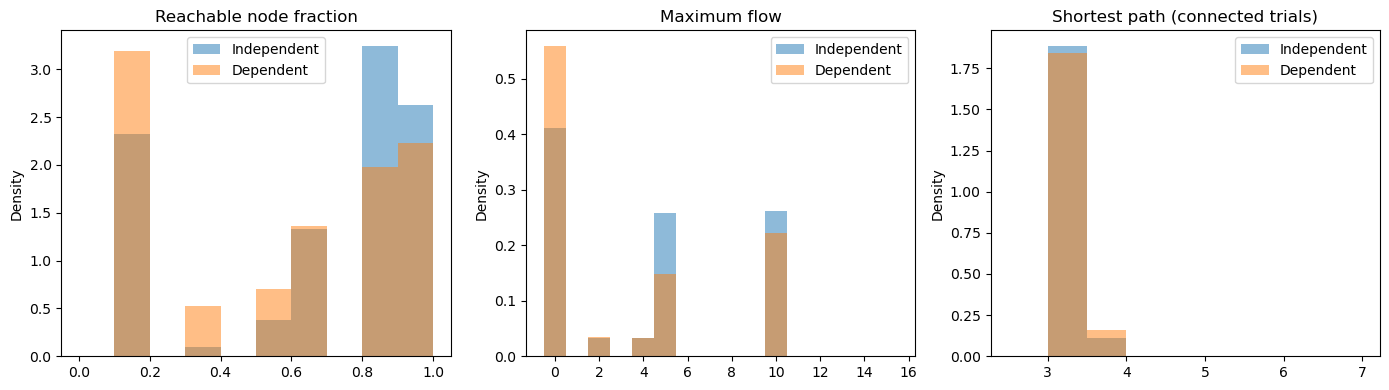

In [2]:
G, results = run_monte_carlo(n_simulations=10_000, p_fail=0.20, seed=123,)
summary = summarize_results(results)
print("\nMonte Carlo comparison:")
print(summary.to_string())

# Distribution comparisons
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for model in ["Independent", "Dependent"]:
    subset = results[results["model"] == model]
    axes[0].hist(subset["reachable_node_fraction"], bins=np.linspace(0, 1, 11), alpha=0.5, label=model, density=True,)
    axes[1].hist(subset["max_flow"], bins=np.arange(-0.5, 16.5, 1), alpha=0.5, label=model, density=True,)
    axes[2].hist(subset["shortest_path_length"].dropna(), bins=np.arange(2.5, 7.1, 0.5), alpha=0.5, label=model, density=True,)

axes[0].set_title("Reachable node fraction")
axes[1].set_title("Maximum flow")
axes[2].set_title("Shortest path (connected trials)")
for ax in axes:
    ax.set_ylabel("Density")
    ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
G = build_graph()

# Assign independent node availability probabilities.
p_available = {node: 0.80 for node in G.nodes}

# Assume source and sink are always operational.
p_available["s"] = 1.0
p_available["t"] = 1.0

p_connect = connectivity_probability(G, "s", "t", p_available)

shortest = shortest_path_distribution(G, "s", "t", p_available)

print(f"Connectivity probability: {p_connect:.4f}")
print("Disconnection probability: " f"{shortest['disconnection_probability']:.4f}")
print("Expected shortest distance, given connected: " f"{shortest['expected_length_given_connected']:.4f}")
print("Shortest-path distribution:")

for length, probability in sorted(shortest["distribution"].items()):
    print(f"  Length {length}: P = {probability:.4f}")

Connectivity probability: 0.9216
Disconnection probability: 0.0784
Expected shortest distance, given connected: 3.0278
Shortest-path distribution:
  Length 3.0: P = 0.8704
  Length 3.5: P = 0.0512


In [2]:
G = build_graph()

nodes: ['s', 'a', 'c', 't', 'b', 'd']
edges: [('s', 'a'), ('s', 'b'), ('a', 'c'), ('a', 'd'), ('c', 't'), ('b', 'd'), ('b', 'c'), ('d', 't')]


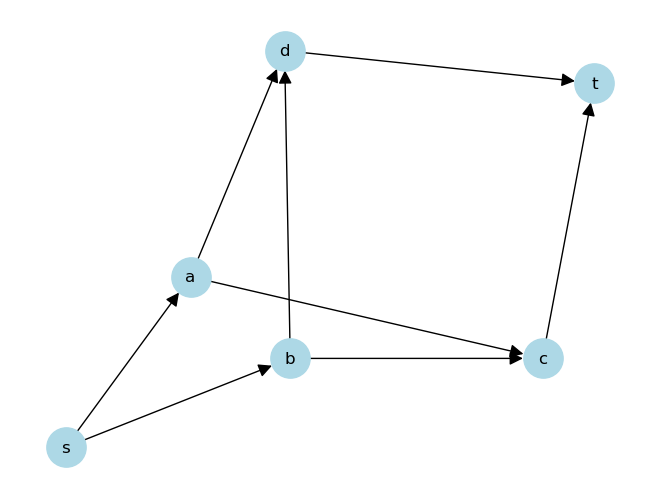

In [13]:
nx.draw(G, with_labels=True, node_color="lightblue", node_size=800, arrowsize=20, pos=nx.spring_layout(G, seed=123))
print(f'nodes: {G.nodes()}')
print(f'edges: {G.edges()}')

A. Common-cause failures
    Two facilities rely on the same electrical grid.
    Two communication nodes depend on the same satellite.
    Two components operate in the same hazardous environment.
    Two servers depend on the same cooling system.

B. Direct functional dependencies
    A distribution facility requires an upstream processing facility.
    A communication relay requires a control node.
    A manufacturing process requires a functioning input supplier.

C. Shared resources and capacity constraints
    Two facilities compete for a limited supply of fuel.
    Two processing nodes share a constrained communication channel.
    Multiple facilities require the same limited pool of personnel.
    Two systems compete for a limited power budget.

D. Shared environmental conditions
    Weather affects multiple transportation nodes.
    A cyberattack affects multiple network devices.
    A natural disaster affects multiple facilities.
    A regional disruption affects several logistics sites.

E. Physical or geographic proximity
    Flooding or fires.
    Extreme temperatures.
    Infrastructure damage.
    Localized power outages.
    Environmental hazards.

In [ ]:
edges = [(0,1), (1,3), (3,5), (0, 2), (2,4), (4,5)]
